# 2.0 - Ingeniería de características

Construye las transformaciones de las features seleccionadas en el EDA (`pipeline_config.yaml` → `MODEL_FEATURES`) y genera los datasets que usaremos en el notebook de modelos.

Pasos (cada uno en su propia sección):
1. Imputación de variables numéricas y categóricas
2. Codificación de variables categóricas
3. Tratamiento de outliers
4. Transformación de variables continuas
5. Escalado de variables

El resultado final es un **`Pipeline` de scikit-learn** con transformadores de **feature-engine**, ajustado solo con el conjunto de entrenamiento.

## 1. Configuración

Importa las librerías, las rutas del proyecto y fija la semilla para que los resultados sean reproducibles.

In [1]:
%load_ext autoreload
%autoreload 2

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from feature_engine.encoding import OneHotEncoder, RareLabelEncoder
from feature_engine.imputation import CategoricalImputer, MeanMedianImputer, RandomSampleImputer
from feature_engine.outliers import Winsorizer
from feature_engine.selection import DropFeatures
from feature_engine.transformation import LogTransformer, YeoJohnsonTransformer
from feature_engine.wrappers import SklearnTransformerWrapper
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

from proyecto_pd.config import FIGURES_DIR, MODELS_DIR, PROCESSED_DATA_DIR, PROJ_ROOT, RAW_DATA_DIR

pd.set_option("display.max_columns", 100)
plt.style.use("ggplot")

SEMILLA = 42

2026-10-29 18:56:50.952 | INFO     | proyecto_pd.config:<module>:11 - PROJ_ROOT path is: C:\Users\doty_\Documents\PD\Proyecto\proyecto_pd


## 2. Carga de datos y features del modelo

Lee las 30 features de `pipeline_config.yaml` y carga `train.csv` y `test.csv` usando `Id` como índice, para conservarlo en los datasets de salida.

In [2]:
with open(PROJ_ROOT / "pipeline_config.yaml", encoding="utf-8") as f:
    MODEL_FEATURES = yaml.safe_load(f)["MODEL_FEATURES"]

train = pd.read_csv(RAW_DATA_DIR / "train.csv", index_col="Id")
test = pd.read_csv(RAW_DATA_DIR / "test.csv", index_col="Id")

X = train[MODEL_FEATURES]
y = train["SalePrice"]
X_test = test[MODEL_FEATURES]

print(f"Features: {len(MODEL_FEATURES)}")
print(f"X: {X.shape} | X_test: {X_test.shape}")

Features: 30
X: (1460, 30) | X_test: (1459, 30)


### 2.1 Grupos de variables

Clasifica las features con los mismos criterios del EDA:
- **Continuas:** numéricas con más de 15 valores distintos.
- **Discretas:** numéricas con 15 o menos valores distintos.
- **Categóricas:** de texto, más `MSSubClass`, que es numérica pero representa un código de tipo de vivienda (se trata como nominal).

Dentro de las categóricas se separan las **ordinales** (tienen un orden natural) de las **nominales**.

In [3]:
UMBRAL_DISCRETAS = 15

ESCALA_CALIDAD = ["Po", "Fa", "TA", "Gd", "Ex"]
ORDINALES = {
    "ExterQual": ESCALA_CALIDAD,
    "BsmtQual": ESCALA_CALIDAD,
    "KitchenQual": ESCALA_CALIDAD,
    "FireplaceQu": ESCALA_CALIDAD,
    "HeatingQC": ESCALA_CALIDAD,
    "GarageFinish": ["Unf", "RFn", "Fin"],
    "BsmtFinType1": ["Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
}
NOMINALES = ["Neighborhood", "Foundation", "GarageType", "MSSubClass"]

categoricas = list(ORDINALES) + NOMINALES
numericas = [col for col in MODEL_FEATURES if col not in categoricas]
continuas = [col for col in numericas if X[col].nunique() > UMBRAL_DISCRETAS]
discretas = [col for col in numericas if col not in continuas]

print(f"Continuas ({len(continuas)}):   {continuas}")
print(f"Discretas ({len(discretas)}):   {discretas}")
print(f"Ordinales ({len(ORDINALES)}):   {list(ORDINALES)}")
print(f"Nominales ({len(NOMINALES)}):   {NOMINALES}")

Continuas (10):   ['GrLivArea', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'MasVnrArea', 'BsmtFinSF1', 'LotFrontage']
Discretas (9):   ['OverallQual', 'GarageCars', 'FullBath', 'TotRmsAbvGrd', 'Fireplaces', 'OverallCond', 'HalfBath', 'BedroomAbvGr', 'BsmtFullBath']
Ordinales (7):   ['ExterQual', 'BsmtQual', 'KitchenQual', 'FireplaceQu', 'HeatingQC', 'GarageFinish', 'BsmtFinType1']
Nominales (4):   ['Neighborhood', 'Foundation', 'GarageType', 'MSSubClass']


## 3. División train / validación

Separa `train.csv` en **80% entrenamiento** y **20% validación**. Todas las transformaciones se ajustan **solo con `X_train`** y después se aplican a validación y test, para evitar fuga de datos.

In [4]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=SEMILLA)

print(f"X_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}")

X_train: (1168, 30) | X_val: (292, 30) | X_test: (1459, 30)


## 4. Paso 1 - Imputación de valores faltantes

### 4.1 Porcentaje de faltantes y regla de imputación

Calcula el % de faltantes de cada variable en `X_train` y le asigna una estrategia:

| % faltantes en train | Numéricas | Categóricas |
|---|---|---|
| ≤ 5% | Mediana | Moda |
| > 5% y ≤ 20% | Muestreo aleatorio de los valores observados | Moda |
| > 20% | Se descarta la variable | Se descarta la variable |

También se muestran los faltantes de `test`: algunas variables solo tienen faltantes ahí, y quedan cubiertas porque el imputador aprende el valor de reemplazo de todas las variables de su grupo.

In [5]:
LIMITE_MEDIANA = 5
LIMITE_DESCARTE = 20

pct_faltantes = X_train.isna().mean() * 100


def estrategia(col):
    if pct_faltantes[col] > LIMITE_DESCARTE:
        return "descartar"
    if col in categoricas:
        return "moda"
    if pct_faltantes[col] <= LIMITE_MEDIANA:
        return "mediana"
    return "aleatorio"


resumen_faltantes = pd.DataFrame({
    "tipo": ["categórica" if col in categoricas else "numérica" for col in MODEL_FEATURES],
    "pct_faltantes_train": pct_faltantes[MODEL_FEATURES].round(2),
    "faltantes_test": X_test[MODEL_FEATURES].isna().sum(),
    "estrategia": [estrategia(col) for col in MODEL_FEATURES],
}, index=MODEL_FEATURES)

vars_descartar = resumen_faltantes.query("estrategia == 'descartar'").index.tolist()
vars_mediana = resumen_faltantes.query("estrategia == 'mediana'").index.tolist()
vars_aleatorio = resumen_faltantes.query("estrategia == 'aleatorio'").index.tolist()
vars_moda = resumen_faltantes.query("estrategia == 'moda'").index.tolist()

print(f"Descartar: {vars_descartar}")
print(f"Aleatorio: {vars_aleatorio}")

resumen_faltantes[(resumen_faltantes["pct_faltantes_train"] > 0) | (resumen_faltantes["faltantes_test"] > 0)]

Descartar: ['FireplaceQu']
Aleatorio: ['GarageYrBlt', 'LotFrontage']


,tipo,pct_faltantes_train,faltantes_test,estrategia
GarageArea,numérica,0.00,1,mediana
TotalBsmtSF,numérica,0.00,1,mediana
GarageYrBlt,numérica,5.48,78,aleatorio
MasVnrArea,numérica,0.51,15,mediana
BsmtFinSF1,numérica,0.00,1,mediana
LotFrontage,numérica,18.58,227,aleatorio
GarageCars,numérica,0.00,1,mediana
BsmtFullBath,numérica,0.00,2,mediana
BsmtQual,categórica,2.40,44,moda
KitchenQual,categórica,0.00,1,moda


### 4.2 Imputadores

Define los transformadores de feature-engine para cada estrategia y los aplica a `X_train` para revisar el resultado:
- `DropFeatures`: elimina las variables con más del 20% de faltantes.
- `MeanMedianImputer`: reemplaza con la mediana.
- `RandomSampleImputer`: reemplaza con valores tomados al azar de los datos observados, así que conserva la forma de la distribución. Usa `seed="observation"`: la semilla de cada casa se calcula con sus propios valores de `VARS_SEMILLA` (sin faltantes en este punto, porque la imputación por mediana va antes). Así, una misma casa recibe siempre el mismo valor imputado, sin importar con qué otras casas se transforme (necesario para que la inferencia sea reproducible).
- `CategoricalImputer`: reemplaza con la moda. `ignore_format=True` permite incluir `MSSubClass`, que es numérica.

In [6]:
VARS_SEMILLA = ["GrLivArea", "YearBuilt", "OverallQual"]

pasos_imputacion = [
    ("descartar_faltantes", DropFeatures(features_to_drop=vars_descartar)),
    ("imputar_mediana", MeanMedianImputer(imputation_method="median", variables=vars_mediana)),
    ("imputar_aleatorio", RandomSampleImputer(variables=vars_aleatorio, random_state=VARS_SEMILLA, seed="observation")),
    ("imputar_moda", CategoricalImputer(imputation_method="frequent", variables=vars_moda, ignore_format=True)),
]

X_train_imp = Pipeline(pasos_imputacion).fit_transform(X_train)

# Actualizar los grupos quitando las variables descartadas
ordinales = {col: escala for col, escala in ORDINALES.items() if col not in vars_descartar}
continuas = [col for col in continuas if col not in vars_descartar]

print(f"Columnas: {X_train.shape[1]} -> {X_train_imp.shape[1]}")
print(f"Faltantes restantes en train: {X_train_imp.isna().sum().sum()}")

Columnas: 30 -> 29
Faltantes restantes en train: 0


### 4.3 Distribución antes y después del muestreo aleatorio

Compara la distribución original (sin faltantes) con la imputada, para verificar que el muestreo aleatorio conserva la forma de los datos.

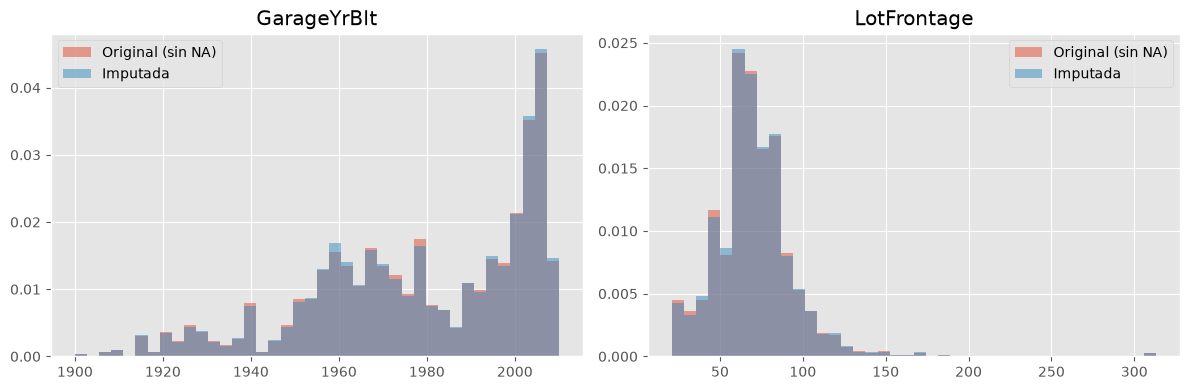

In [7]:
fig, axes = plt.subplots(1, len(vars_aleatorio), figsize=(6 * len(vars_aleatorio), 4), squeeze=False)
for ax, col in zip(axes.flat, vars_aleatorio):
    ax.hist(X_train[col].dropna(), bins=40, density=True, alpha=0.5, label="Original (sin NA)")
    ax.hist(X_train_imp[col], bins=40, density=True, alpha=0.5, label="Imputada")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fe_imputacion_aleatoria.png")
plt.show()

## 5. Paso 2 - Codificación de variables categóricas

### 5.1 Variables ordinales: mapeo manual

Convierte cada categoría en un número según el orden real de su escala, con `OrdinalEncoder` de sklearn envuelto en `SklearnTransformerWrapper` de feature-engine. Así se mantiene el DataFrame.

Cada escala empieza con un marcador `"Ausente"` = 0, de modo que `Po` = 1, `Fa` = 2, `TA` = 3, `Gd` = 4, `Ex` = 5. Tras la imputación por moda no debería aparecer `"Ausente"`. Una categoría que no se vio en train se codifica como -1.

In [8]:
codificador_ordinal = SklearnTransformerWrapper(
    transformer=OrdinalEncoder(
        categories=[["Ausente"] + escala for escala in ordinales.values()],
        handle_unknown="use_encoded_value",
        unknown_value=-1,
    ),
    variables=list(ordinales),
)

X_train_ord = codificador_ordinal.fit_transform(X_train_imp)

# Verificación: tabla de categoría original -> código
pd.concat(
    {col: pd.crosstab(X_train_imp[col], X_train_ord[col]).idxmax(axis=1) for col in ordinales},
    names=["variable", "categoria"],
).rename("codigo").to_frame().T

variable  ExterQual                BsmtQual                KitchenQual       \
categoria        Ex   Fa   Gd   TA       Ex   Fa   Gd   TA          Ex   Fa   
codigo          5.0  2.0  4.0  3.0      5.0  2.0  4.0  3.0         5.0  2.0   

variable            HeatingQC                     GarageFinish            \
categoria   Gd   TA        Ex   Fa   Gd   Po   TA          Fin  RFn  Unf   
codigo     4.0  3.0       5.0  2.0  4.0  1.0  3.0          3.0  2.0  1.0   

variable  BsmtFinType1                           
categoria          ALQ  BLQ  GLQ  LwQ  Rec  Unf  
codigo             5.0  4.0  6.0  2.0  3.0  1.0

### 5.2 Variables nominales: agrupar categorías raras + one-hot

1. `RareLabelEncoder` agrupa en `"Rare"` las categorías con menos del **1%** de las casas en train. También envía a `"Rare"` las categorías nuevas que aparezcan en validación o test. `n_categories=1` hace que se aplique a todas las nominales, sin importar cuántas categorías tengan.
2. `OneHotEncoder` crea una columna 0/1 por categoría.

In [9]:
agrupador_raras = RareLabelEncoder(
    tol=0.01, n_categories=1, variables=NOMINALES, replace_with="Rare", ignore_format=True
)
one_hot = OneHotEncoder(variables=NOMINALES, ignore_format=True)

X_train_rare = agrupador_raras.fit_transform(X_train_ord)
X_train_cod = one_hot.fit_transform(X_train_rare)

for col in NOMINALES:
    print(f"{col}: {X_train_ord[col].nunique()} categorías -> {X_train_rare[col].nunique()} (con 'Rare')")
print(f"\nColumnas: {X_train_ord.shape[1]} -> {X_train_cod.shape[1]}")

Neighborhood: 25 categorías -> 22 (con 'Rare')
Foundation: 6 categorías -> 5 (con 'Rare')
GarageType: 6 categorías -> 5 (con 'Rare')
MSSubClass: 15 categorías -> 13 (con 'Rare')

Columnas: 29 -> 70


## 6. Paso 3 - Tratamiento de outliers

Recorta (*capping*) los valores extremos de las **variables continuas** con `Winsorizer`, usando el método IQR:
- Límite inferior = Q1 − 1.5·IQR
- Límite superior = Q3 + 1.5·IQR

Los valores fuera de esos límites se reemplazan por el límite. No se eliminan filas. Los límites se aprenden de train.

In [10]:
capping = Winsorizer(capping_method="iqr", tail="both", fold=1.5, variables=continuas)

X_train_out = capping.fit_transform(X_train_cod)

pd.DataFrame({
    "limite_inferior": capping.left_tail_caps_,
    "limite_superior": capping.right_tail_caps_,
    "recortados_inferior": {c: (X_train_cod[c] < capping.left_tail_caps_[c]).sum() for c in continuas},
    "recortados_superior": {c: (X_train_cod[c] > capping.right_tail_caps_[c]).sum() for c in continuas},
}).round(1)

,limite_inferior,limite_superior,recortados_inferior,recortados_superior
GrLivArea,176.4,2761.4,0,23
GarageArea,-11.5,928.5,0,18
TotalBsmtSF,41.1,2054.1,28,19
1stFlrSF,124.9,2159.9,0,13
YearBuilt,1881.0,2073.0,5,0
YearRemodAdd,1909.0,2061.0,0,0
GarageYrBlt,1899.5,2063.5,0,0
MasVnrArea,-249.0,415.0,0,77
BsmtFinSF1,-1081.5,1802.5,0,5
LotFrontage,27.5,111.5,36,46


## 7. Paso 4 - Transformación de variables continuas

Aplica una transformación a las continuas con alto sesgo (|skew| > 0.75 en el EDA):
- **Logaritmo** (`LogTransformer`) para las que no tienen ceros: `LotFrontage`, `1stFlrSF`, `GrLivArea`.
- **Yeo-Johnson** (`YeoJohnsonTransformer`) para las que tienen ceros: `MasVnrArea`, `BsmtFinSF1`, `TotalBsmtSF`.

La tabla compara la asimetría antes y después de la transformación.

In [11]:
VARS_LOG = ["LotFrontage", "1stFlrSF", "GrLivArea"]
VARS_YEO_JOHNSON = ["MasVnrArea", "BsmtFinSF1", "TotalBsmtSF"]

transformador_log = LogTransformer(variables=VARS_LOG)
transformador_yj = YeoJohnsonTransformer(variables=VARS_YEO_JOHNSON)

X_train_tr = transformador_yj.fit_transform(transformador_log.fit_transform(X_train_out))

pd.DataFrame({
    "transformacion": ["log"] * len(VARS_LOG) + ["yeo-johnson"] * len(VARS_YEO_JOHNSON),
    "skew_original": X_train[VARS_LOG + VARS_YEO_JOHNSON].skew(),
    "skew_tras_capping": X_train_out[VARS_LOG + VARS_YEO_JOHNSON].skew(),
    "skew_transformada": X_train_tr[VARS_LOG + VARS_YEO_JOHNSON].skew(),
}).round(2)

,transformacion,skew_original,skew_tras_capping,skew_transformada
LotFrontage,log,2.41,0.11,-0.79
1stFlrSF,log,1.42,0.61,-0.12
GrLivArea,log,1.43,0.59,-0.19
MasVnrArea,yeo-johnson,2.29,1.27,0.37
BsmtFinSF1,yeo-johnson,1.86,0.73,-0.42
TotalBsmtSF,yeo-johnson,1.72,0.24,0.05


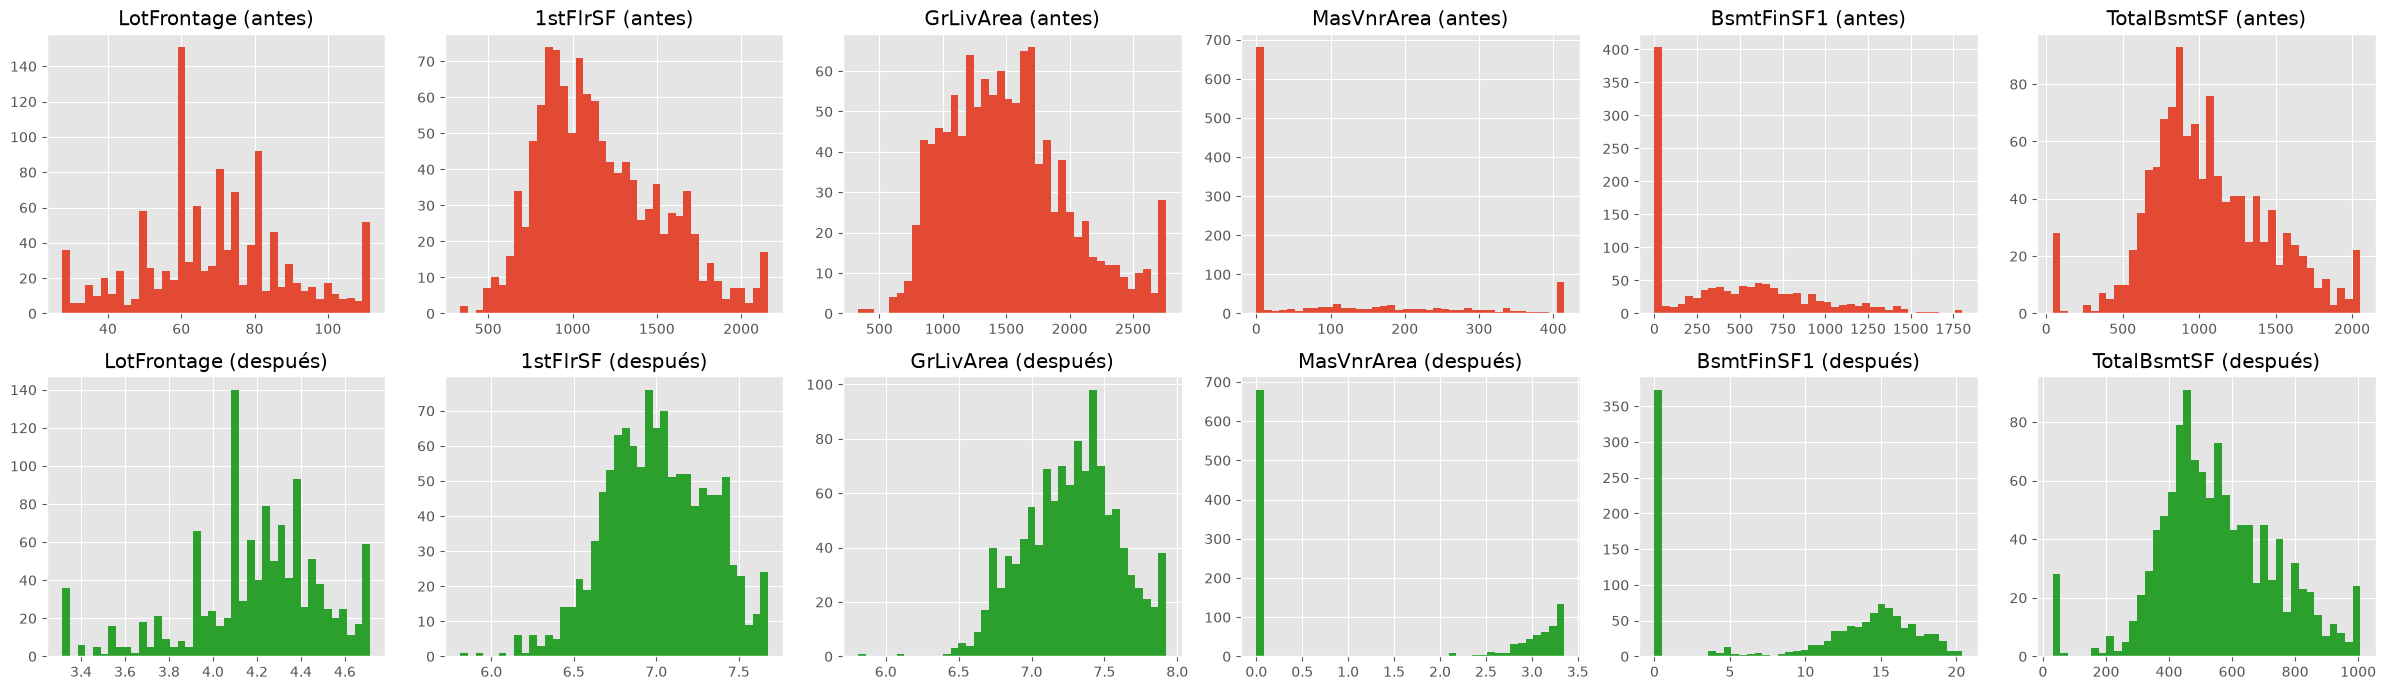

In [12]:
columnas_tr = VARS_LOG + VARS_YEO_JOHNSON
fig, axes = plt.subplots(2, len(columnas_tr), figsize=(4 * len(columnas_tr), 7))
for i, col in enumerate(columnas_tr):
    axes[0, i].hist(X_train_out[col], bins=40)
    axes[0, i].set_title(f"{col} (antes)")
    axes[1, i].hist(X_train_tr[col], bins=40, color="tab:green")
    axes[1, i].set_title(f"{col} (después)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fe_transformaciones.png")
plt.show()

## 8. Paso 5 - Escalado

Estandariza **todas** las columnas (media 0, desviación estándar 1) con `StandardScaler`, envuelto en `SklearnTransformerWrapper` para mantener el DataFrame y los nombres de las columnas.

In [13]:
escalador = SklearnTransformerWrapper(transformer=StandardScaler())

X_train_esc = escalador.fit_transform(X_train_tr)

X_train_esc.describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
GrLivArea,0.0,1.0,-4.57,2.03
GarageArea,0.0,1.0,-2.31,2.22
TotalBsmtSF,-0.0,1.0,-2.77,2.42
1stFlrSF,-0.0,1.0,-3.85,2.14
YearBuilt,-0.0,1.0,-2.94,1.27
...,...,...,...,...
MSSubClass_160,-0.0,1.0,-0.21,4.78
MSSubClass_190,-0.0,1.0,-0.16,6.38
MSSubClass_75,-0.0,1.0,-0.11,8.77
MSSubClass_120,-0.0,1.0,-0.24,4.15


## 9. Pipeline final

Une todos los pasos anteriores en un único `Pipeline` de sklearn. `clone` crea una copia **sin ajustar** de cada transformador; el pipeline se ajusta con `X_train` y después transforma validación y test.

Al final se verifica que:
- No quedan faltantes.
- Los tres conjuntos tienen las mismas columnas.
- El resultado coincide con el que obtuvimos paso a paso.

In [14]:
pipeline_fe = clone(Pipeline(
    pasos_imputacion
    + [
        ("codificar_ordinales", codificador_ordinal),
        ("agrupar_raras", agrupador_raras),
        ("one_hot", one_hot),
        ("capping_outliers", capping),
        ("transformar_log", transformador_log),
        ("transformar_yeo_johnson", transformador_yj),
        ("escalar", escalador),
    ]
))

X_train_fe = pipeline_fe.fit_transform(X_train)
X_val_fe = pipeline_fe.transform(X_val)
X_test_fe = pipeline_fe.transform(X_test)

print(f"X_train_fe: {X_train_fe.shape} | X_val_fe: {X_val_fe.shape} | X_test_fe: {X_test_fe.shape}")
print(f"Faltantes -> train: {X_train_fe.isna().sum().sum()}, val: {X_val_fe.isna().sum().sum()}, test: {X_test_fe.isna().sum().sum()}")
print(f"Mismas columnas en los 3 conjuntos: {list(X_train_fe.columns) == list(X_val_fe.columns) == list(X_test_fe.columns)}")
print(f"Igual al resultado paso a paso: {np.allclose(X_train_fe, X_train_esc)}")

pipeline_fe

X_train_fe: (1168, 70) | X_val_fe: (292, 70) | X_test_fe: (1459, 70)
Faltantes -> train: 0, val: 0, test: 0
Mismas columnas en los 3 conjuntos: True
Igual al resultado paso a paso: True


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('descartar_faltantes', ...), ('imputar_mediana', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0",list,"['Gr...ea', 'Ga...ea', 'To...SF', '1s...SF', ...]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,features_to_drop,['FireplaceQu']
Name,Type,Value
feature_names_in_,list,"['Gr...ea', 'Ga...ea', 'To...SF', '1s...SF', ...]"
features_to_drop_,list,['Fi...Qu']


## 10. Target

Agrega al dataset el precio original (`SalePrice`) y su logaritmo (`SalePrice_log = log(1 + SalePrice)`). En el notebook de modelos se decide cuál usar; la métrica de Kaggle es el RMSE sobre el logaritmo.

In [15]:
def armar_dataset(X_fe, y=None):
    df = X_fe.copy()
    if y is not None:
        df["SalePrice"] = y
        df["SalePrice_log"] = np.log1p(y)
    return df.reset_index()


train_fe = armar_dataset(X_train_fe, y_train)
val_fe = armar_dataset(X_val_fe, y_val)
test_fe = armar_dataset(X_test_fe)

train_fe[["Id", "SalePrice", "SalePrice_log"]].describe().round(2)

,Id,SalePrice,SalePrice_log
count,1168.00,1168.00,1168.00
mean,730.90,181441.54,12.03
std,425.37,77263.58,0.39
min,1.00,34900.00,10.46
25%,360.75,130000.00,11.78
50%,732.50,165000.00,12.01
75%,1101.75,214925.00,12.28
max,1460.00,745000.00,13.52


## 11. Guardar datasets y pipeline

Guarda los insumos para el notebook de modelos:
- `data/processed/train_fe.csv`, `validacion_fe.csv` y `test_fe.csv`: features transformadas, `Id` y, en train y validación, el target.
- `models/pipeline_fe.joblib`: el pipeline ajustado, para transformar datos nuevos de la misma forma.

In [16]:
train_fe.to_csv(PROCESSED_DATA_DIR / "train_fe.csv", index=False)
val_fe.to_csv(PROCESSED_DATA_DIR / "validacion_fe.csv", index=False)
test_fe.to_csv(PROCESSED_DATA_DIR / "test_fe.csv", index=False)
joblib.dump(pipeline_fe, MODELS_DIR / "pipeline_fe.joblib")

for nombre in ["train_fe.csv", "validacion_fe.csv", "test_fe.csv"]:
    print(f"{nombre}: {pd.read_csv(PROCESSED_DATA_DIR / nombre).shape}")
print(f"Pipeline guardado en: {MODELS_DIR / 'pipeline_fe.joblib'}")

train_fe.csv: (1168, 73)
validacion_fe.csv: (292, 73)
test_fe.csv: (1459, 71)
Pipeline guardado en: C:\Users\doty_\Documents\PD\Proyecto\proyecto_pd\models\pipeline_fe.joblib
